# Front-of-Package Nutrition Label RCT Analysis (Grummon et al., 2025 Benchmark)

In [1]:
# Step 1: Import Grummon OLS estimation utilities and load the Grummon et al. (2025) FOP nutrition label RCT dataset
import importlib
import matplotlib.pyplot as plt
import pandas as pd
import grummon_ols

importlib.reload(grummon_ols)
from grummon_ols import (
    build_grummon_coef_table,
    build_grummon_summary_table,
    evaluate_grummon_metrics,
    fit_grummon_ols,
    load_all_model_regressions,
    load_grummon_rct,
    load_single_attr_ce_table,
    plot_grummon_coefs_and_attributes,
    plot_grummon_error_comparison,
    subsample_grummon_participants,
)

raw_df = load_grummon_rct()
print(
    f"Loaded {len(raw_df):,} three-option product choice tasks across {raw_df['CASEID'].nunique():,} participants "
    f"and {raw_df['arm'].nunique()} randomized FOP labeling arms (d=5 treatment effects vs. 'Positive')"
)

Loaded 33,798 three-option product choice tasks across 5,633 participants and 6 randomized FOP labeling arms (d=5 treatment effects vs. 'Positive')


In [2]:
# Step 2: Fit full-sample human ground-truth HC1 OLS regression (beta*, N = 5,633 participants, 33,798 tasks)
human_ols_df = fit_grummon_ols(raw_df)
beta_star = human_ols_df["beta"].copy()

# Step 3: Subsample 200 participants (1,200 choice tasks, seed=42) and fit Human Subsample Baseline HC1 OLS (beta_sub)
N_LLM_PARTICIPANTS = 200
SUBSAMPLE_SEED = 42

sub_df = subsample_grummon_participants(raw_df, n_participants=N_LLM_PARTICIPANTS, seed=SUBSAMPLE_SEED)
human_sub_ols_df = fit_grummon_ols(sub_df)
beta_human_sub = human_sub_ols_df["beta"].copy()
human_sub_metrics = evaluate_grummon_metrics(beta_human_sub, beta_star)

print(
    f"Human Subsample Baseline (N={sub_df['CASEID'].nunique()}, n={len(sub_df):,} tasks) vs. Full Human (beta*): "
    f"MAPE = {human_sub_metrics['MAPE (%)']:.2f}%, MSE = {human_sub_metrics['MSE']:.4f}, "
    f"Spearman rho = {human_sub_metrics['Spearman rho']:+.2f}"
)
human_sub_ols_df.assign(full_human_beta=beta_star, diff=beta_human_sub - beta_star).round(4)

Human Subsample Baseline (N=200, n=1,200 tasks) vs. Full Human (beta*): MAPE = 22.66%, MSE = 0.0016, Spearman rho = +0.40


,arm,beta,se,z,p_value,full_human_beta,diff
label,,,,,,,
Nutrition Info label (vs. Positive),NutritionInfo,0.1031,0.0759,1.3585,0.1743,0.1844,-0.0813
High In warning label (vs. Positive),HighIn,0.0365,0.0692,0.5267,0.5984,0.0541,-0.0176
Positive + Nutrition Info (vs. Positive),Positive+NutritionInfo,0.2031,0.0655,3.1006,0.0019,0.1788,0.0243
Positive + High In (vs. Positive),Positive+HighIn,0.1317,0.0671,1.9618,0.0498,0.1194,0.0123
Spectrum 1-to-5 star label (vs. Positive),Spectrum,0.1222,0.0696,1.7565,0.0790,0.1083,0.0139


# Kev Model Predictions, Choice Cross-Entropy, & HC1 OLS Regressions

In [3]:
# Step 4: Discover canonical newvalid Kev Grummon JSONL datasets in data/ and fit HC1 OLS regressions
model_ols_dfs, ce_stats = load_all_model_regressions(sub_df, kev_data_dir="data", only_newvalid_ft=True)
print(f"Loaded and fitted {len(model_ols_dfs)} canonical Kev model datasets:")
for name in model_ols_dfs:
    info = ce_stats[name]
    print(f" - {name}: T={info['temperature']:.2f}, CE={info['ce_nats']:.4f} nats ({info['ce_bits']:.4f} bits)")

Loaded and fitted 12 canonical Kev model datasets:
 - jaredpalmer/kev-0.8b (Respondent Persona, N=200, n=1200): T=2.35, CE=1.1182 nats (1.6132 bits)
 - jaredpalmer/kev-0.8b (Random Persona, N=200, n=1200): T=2.35, CE=1.1662 nats (1.6825 bits)
 - kev-0.8b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, N=200, n=1200): T=1.00, CE=1.1508 nats (1.6602 bits)
 - kev-0.8b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, N=200, n=1200): T=1.00, CE=1.1743 nats (1.6942 bits)
 - jaredpalmer/kev-4b (Respondent Persona, N=200, n=1200): T=2.41, CE=1.1760 nats (1.6966 bits)
 - jaredpalmer/kev-4b (Random Persona, N=200, n=1200): T=2.41, CE=0.9692 nats (1.3983 bits)
 - kev-4b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, N=200, n=1200): T=1.00, CE=1.0433 nats (1.5052 bits)
 - kev-4b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, N=200, n=1200): T=1.00, CE=1.0075 nats (1.4536 bits)
 - jaredpalmer/kev-9b (Respondent Persona, N=200, n=1200): T=2.19, CE=1.1227 nats

In [4]:
# Step 5: Compare all Kev estimators against Full Human (beta*) and Human Subsample (beta_sub)
human_sub_key = f"Human Subsample Baseline (N={sub_df['CASEID'].nunique()}, n={len(sub_df)})"
estimators_beta = {
    human_sub_key: beta_human_sub,
    **{name: df_m["beta"] for name, df_m in model_ols_dfs.items()},
}

comparison_rows = {}
for name, b_hat in estimators_beta.items():
    vs_full = evaluate_grummon_metrics(b_hat, beta_star)
    vs_sub = evaluate_grummon_metrics(b_hat, beta_human_sub)
    comparison_rows[name] = {
        "MAPE vs. Full Human (%)": vs_full["MAPE (%)"],
        "MSE vs. Full Human": vs_full["MSE"],
        "Spearman rho vs. Full Human": vs_full["Spearman rho"],
        "MAPE vs. Human Subsample (%)": vs_sub["MAPE (%)"],
        "MSE vs. Human Subsample": vs_sub["MSE"],
    }

comparison_metrics_df = pd.DataFrame(comparison_rows).T.sort_values("MSE vs. Full Human", ascending=True)
summary_table_df = build_grummon_summary_table(comparison_metrics_df, ce_stats, human_sub_key=human_sub_key)
coef_table_df = build_grummon_coef_table(human_ols_df, human_sub_ols_df, model_ols_dfs, persona_mode="Respondent Persona")
single_attr_ce_df = load_single_attr_ce_table(sub_df, ablation_dir="data/persona_ablation")

print("=== Publication Summary Table (Section 5.3) ===")
display(summary_table_df)
print("\n=== Arm-Level HC1 OLS Coefficients & SEs (Respondent Persona) ===")
display(coef_table_df)
print("\n=== Single-Attribute Choice Cross-Entropy (nats): Seen (5) vs. Unseen (5) Shopper Attributes ===")
display(single_attr_ce_df.round(4))

=== Publication Summary Table (Section 5.3) ===


,Estimator,Random CE (nats),Random MAPE (%),Random MSE,Respondent CE (nats),Respondent MAPE (%),Respondent MSE,Spearman rho
0,"Human subsample (N = 200, n = 1,200)",—,—,—,—,22.7%,0.0016,+0.40
1,Kev 0.8B (base),1.1662,86.4%,0.0112,1.1182,81.5%,0.0116,-0.40
2,Kev 0.8B FT,1.1743,53.4%,0.0078,1.1508,63.9%,0.0098,+0.20
3,Kev 4B (base),0.9692,34.2%,0.0021,1.1760,77.4%,0.0076,+0.80
4,Kev 4B FT,1.0075,93.0%,0.0106,1.0433,99.6%,0.0122,+0.90
5,Kev 9B (base),1.1098,64.9%,0.0069,1.1227,62.8%,0.0051,+1.00
6,Kev 9B FT,0.9629,66.2%,0.0056,0.9607,70.5%,0.0056,+0.90



=== Arm-Level HC1 OLS Coefficients & SEs (Respondent Persona) ===


,Trial arm (vs. Positive),"Full human (N = 5,633)",Human subsample (N = 200),Kev 0.8B (base),Kev 0.8B FT,Kev 4B (base),Kev 4B FT,Kev 9B (base),Kev 9B FT
0,Nutrition Info label (vs. Positive),+0.184 (0.012),+0.103 (0.076),+0.032 (0.002),+0.062 (0.004),+0.079 (0.004),+0.064 (0.003),+0.137 (0.009),+0.153 (0.003)
1,Positive + Nutrition Info (vs. Positive),+0.179 (0.012),+0.203 (0.066),+0.038 (0.002),+0.051 (0.004),+0.102 (0.004),+0.063 (0.003),+0.132 (0.009),+0.146 (0.003)
2,Positive + High In (vs. Positive),+0.119 (0.012),+0.132 (0.067),+0.059 (0.002),-0.004 (0.005),+0.013 (0.003),-0.009 (0.003),+0.031 (0.004),-0.001 (0.002)
3,Spectrum 1-to-5 star label (vs. Positive),+0.108 (0.012),+0.122 (0.070),+0.024 (0.003),+0.065 (0.004),+0.051 (0.004),+0.030 (0.003),+0.005 (0.006),+0.078 (0.003)
4,High In warning label (vs. Positive),+0.054 (0.012),+0.036 (0.069),+0.118 (0.002),+0.033 (0.004),-0.024 (0.003),-0.048 (0.003),+0.004 (0.004),-0.048 (0.002)



=== Single-Attribute Choice Cross-Entropy (nats): Seen (5) vs. Unseen (5) Shopper Attributes ===


,Attribute group,Code,Shopper attribute,Kev 0.8B (base),Kev 0.8B FT,Kev 4B (base),Kev 4B FT,Kev 9B (base),Kev 9B FT
0,Seen in training,SEX,Sex,1.2640,1.1959,1.1641,1.0194,1.0199,0.9437
1,Seen in training,AGE,Age,1.1587,1.1731,1.0765,1.0140,1.0357,0.9610
2,Seen in training,EDULEVEL,Education,1.1755,1.1803,1.5429,1.0164,1.0610,0.9544
3,Seen in training,US_INC,Income,1.1076,1.1444,1.2597,1.0217,1.0150,0.9635
4,Seen in training,RACE,Race,1.1451,1.1675,1.1528,1.0137,1.0433,0.9502
5,Unseen in training,HISPANIC,Hispanic or Latino,1.2255,1.1775,1.1432,1.0229,1.0422,0.9584
6,Unseen in training,SNAP,SNAP / Food Stamps recipient,1.2546,1.1705,1.2244,1.0253,1.0539,0.9785
7,Unseen in training,NFPUSE,Nutrition Facts label usage,1.0879,1.1731,1.1399,1.0261,1.1933,0.9759
8,Unseen in training,ONLINEAMT,Share of groceries bought online,1.1344,1.1257,1.7025,1.0305,1.1278,0.9756
9,Unseen in training,HEALTHLIT,Nutrition literacy score,1.1540,1.1626,1.0555,1.0236,1.0731,0.9483


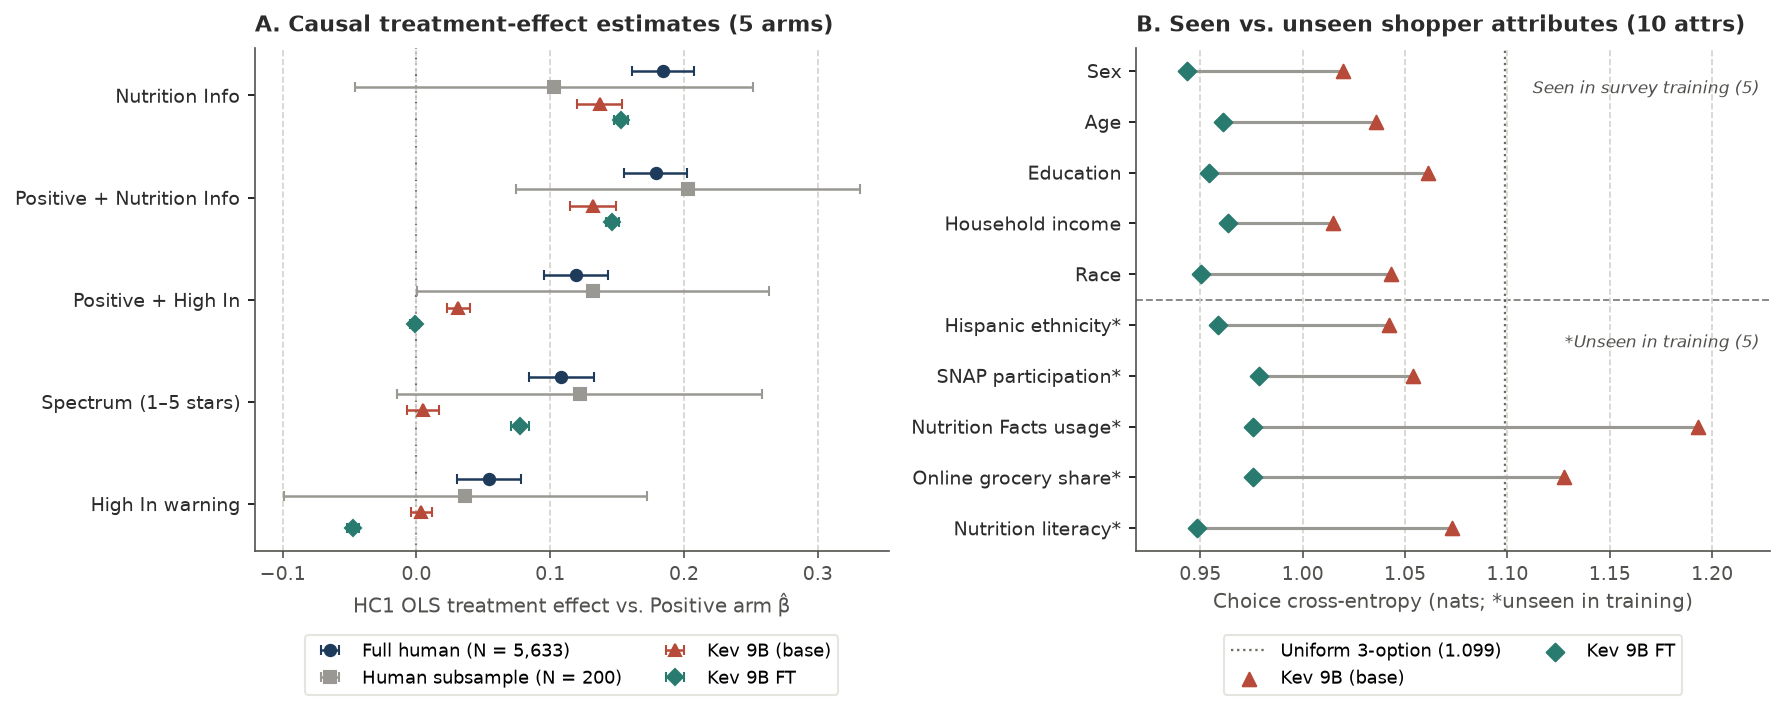

In [5]:
# Step 6: Plot main-text two-panel figure (Panel A: OLS treatment effects; Panel B: Seen vs. Unseen attributes)
fig_coefs = plot_grummon_coefs_and_attributes(
    human_ols_df,
    human_sub_ols_df,
    model_ols_dfs,
    single_attr_ce_df,
    palette="nature",
    persona_mode="Respondent Persona",
)
fig_coefs.savefig("grummon_ols_coefs.png", dpi=300, bbox_inches="tight")
fig_coefs.savefig("grummon_ols_coefs.pdf", bbox_inches="tight")
plt.show()

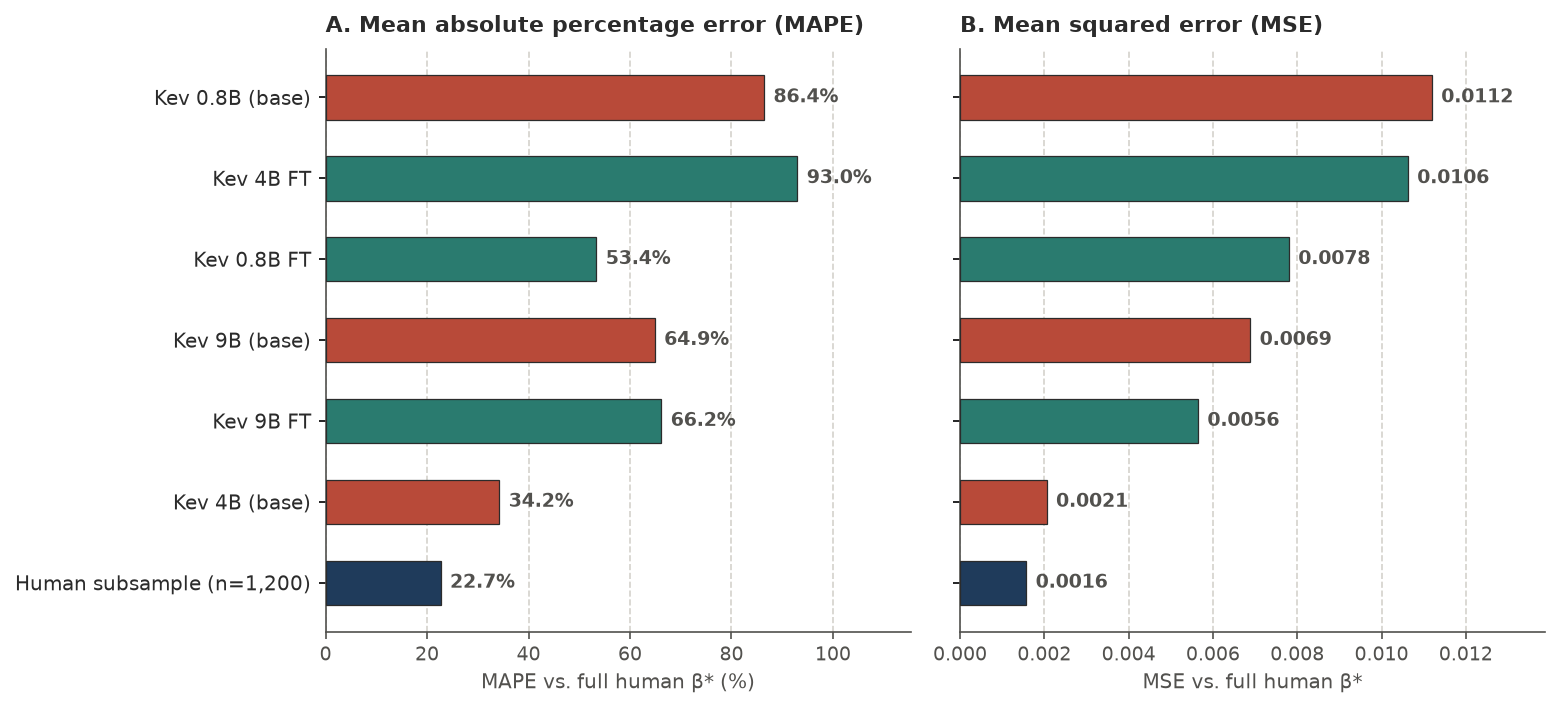

In [6]:
# Step 7a: Plot Random Persona Kev models (plus Human Subsample Baseline) sorted best-to-worst on MSE vs. Full Human
fig_random = plot_grummon_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Random Persona",
    sort_by="MSE vs. Full Human",
)
fig_random.savefig("grummon_ols_random.png", dpi=300, bbox_inches="tight")
fig_random.savefig("grummon_ols_random.pdf", bbox_inches="tight")
plt.show()

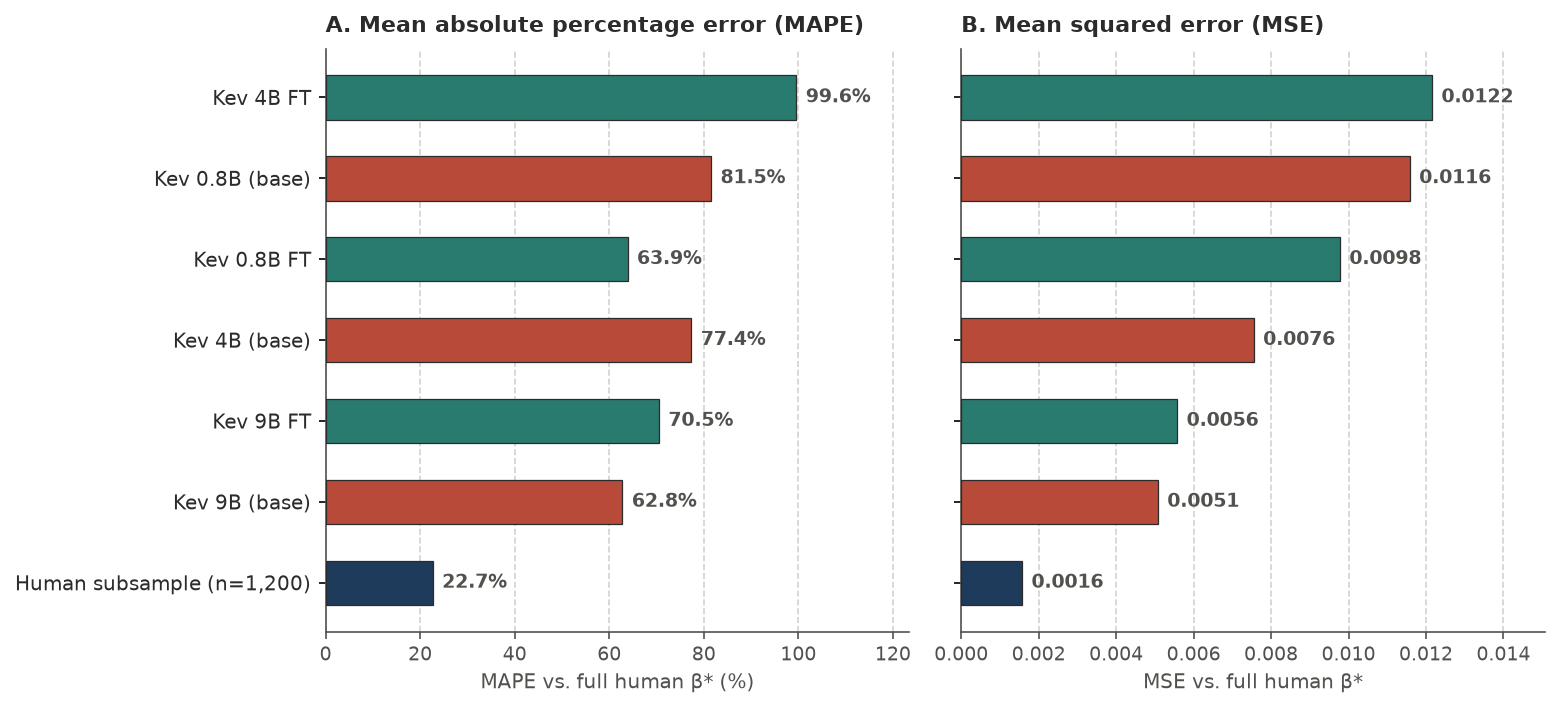

In [7]:
# Step 7b: Plot Respondent Persona Kev models (plus Human Subsample Baseline) sorted best-to-worst on MSE vs. Full Human
fig_persona = plot_grummon_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Respondent Persona",
    sort_by="MSE vs. Full Human",
)
fig_persona.savefig("grummon_ols_persona.png", dpi=300, bbox_inches="tight")
fig_persona.savefig("grummon_ols_persona.pdf", bbox_inches="tight")
plt.show()